# Discrete Evolutionary Search for Parameter-Efficient LLM Adaptation Under Strict Evaluation Budgets

**Name:** Rediet Girmay &nbsp; | &nbsp; **ID:** GSE-0945-17  
*School of Information Technology and Engineering, Addis Ababa University*

---

## Framework & Empirical Validation Overview

This notebook implements and validates the **Discrete Evolutionary Search Framework (DESF) (Genetic Algorithm — GA with elitism, uniform crossover, and categorical mutation)** for Low-Rank Adaptation (LoRA) hyperparameter selection under an ultra-low evaluation budget ($B \le 8$).

### Research Framing
- **Proposed Method:** Discrete Evolutionary Search Framework (structured population-based search with elitism, uniform crossover, and categorical mutation)
- **SOTA Baseline:** Optuna-TPE (Tree-structured Parzen Estimator Bayesian Optimisation)
- **Comparative Search Strategies:** Particle Swarm Optimisation (PSO) & Simulated Annealing (SA)

### Discrete Configuration Space $\mathcal{X}$
```
r        ∈ {2, 4, 8}           # LoRA rank
alpha    ∈ {8, 16, 32}         # LoRA scaling factor
lr       ∈ {1e-4, 2e-4, 3e-4}  # Learning rate
dropout  ∈ {0.05, 0.10}        # LoRA dropout
─────────────────────────────
|X| = 3 × 3 × 3 × 2 = 54 configurations
Strict Budget B = 8  →  8/54 ≈ 14.8% of search space explored
```

### Formal Objective & Fitness Function
$$f(r, \alpha, \eta, p) = -\mathcal{L}_{\text{train}}(\theta_{\text{LoRA}})$$
The framework maximises $f$ (minimising training loss on instruction tuning split).

### Experimental Infrastructure
- **Model Backbone:** `meta-llama/Llama-3.2-3B-Instruct` (4-bit NF4 quantisation via QLoRA)
- **Dataset:** `tatsu-lab/alpaca` (200 instruction-following examples, 64-token limit)
- **Environment:** Google Colab T4 GPU (16 GB VRAM)
- **Runtime:** ~60–70 minutes total


## Cell 1 · Environment Setup — Dependencies & GPU Verification

In [1]:
# ── Cell 1: Install dependencies & verify GPU ─────────────────────────────────
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

print("=== Installing required libraries ===")
!pip install -q --upgrade accelerate transformers datasets peft bitsandbytes optuna scipy matplotlib
print("✅ All dependencies installed successfully.\n")

import torch
cuda_ok = torch.cuda.is_available()
print(f"CUDA status : {cuda_ok}")
if cuda_ok:
    print(f"GPU Name    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM        : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    raise RuntimeError(
        "\n❌ GPU not detected!\n"
        "Please switch runtime: Runtime → Change runtime type → T4 GPU"
    )

=== Installing required libraries ===
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 4.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 107.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 46.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 60.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 103.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 15.9 MB/s eta 0:00:00
✅ All dependencies installed successfully.

CUDA status : True
GPU Name    : Tesl

## Cell 2 · Backbone Initialization — Llama-3.2-3B-Instruct (4-bit NF4 QLoRA)

- Quantised to **4-bit NormalFloat (NF4)** using `bitsandbytes` to constrain memory footprint
- Base model weights are **completely frozen**; only LoRA parameter adapters are trainable
- Double quantisation enabled to maximize memory efficiency

In [2]:
# ── Cell 2: Load quantized model backbone ────────────────────────────────────
from huggingface_hub import login
from getpass import getpass
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
import torch

MODEL_NAME = "meta-llama/Llama-3.2-3B-Instruct"

HF_TOKEN = getpass("Enter Hugging Face access token: ")
login(HF_TOKEN)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
)

print(f"Loading {MODEL_NAME} in 4-bit NF4 QLoRA configuration...")

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
    token=HF_TOKEN,
)
model.config.use_cache = False

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True, token=HF_TOKEN)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print(f"✅ Base model loaded ({model.num_parameters() / 1e9:.2f}B parameters, frozen).")

Enter Hugging Face access token: ··········
Loading meta-llama/Llama-3.2-3B-Instruct in 4-bit NF4 QLoRA configuration...


config.json:   0%|          | 0.00/878 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

✅ Base model loaded (3.21B parameters, frozen).


## Cell 3 · Dataset Preparation — Alpaca Instruction Subset

- **Source:** `tatsu-lab/alpaca` instruction dataset
- **Subset Size:** 200 instruction-response pairs
- **Sequence Length:** Truncated/padded to 64 tokens for uniform evaluation speed

In [3]:
# ── Cell 3: Load and tokenize dataset ────────────────────────────────────────
from datasets import load_dataset

TRAIN_SIZE = 200
MAX_LEN    = 64

print(f"Preparing instruction split ({TRAIN_SIZE} samples, max length {MAX_LEN})...")
dataset = load_dataset("tatsu-lab/alpaca")
dataset_train = dataset["train"].select(range(TRAIN_SIZE))

def format_alpaca(ex):
    instr = ex["instruction"].strip()
    inp   = ex["input"].strip()
    out   = ex["output"].strip()
    if inp:
        text = (
            f"Below is an instruction that describes a task, paired with an input "
            f"that provides further context.\nWrite a response that appropriately "
            f"completes the request.\n\n### Instruction:\n{instr}\n\n"
            f"### Input:\n{inp}\n\n### Response:\n{out}"
        )
    else:
        text = (
            f"Below is an instruction that describes a task.\nWrite a response "
            f"that appropriately completes the request.\n\n### Instruction:\n"
            f"{instr}\n\n### Response:\n{out}"
        )
    return {"text": text}

def tokenize(ex):
    enc = tokenizer(
        ex["text"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LEN,
        return_attention_mask=True,
        return_tensors="pt",
    )
    d = {k: v.numpy().tolist() for k, v in enc.items()}
    d["labels"] = enc["input_ids"].numpy().tolist()
    return d

dataset_train_fmt = dataset_train.map(format_alpaca, num_proc=2)
dataset_train_tok = dataset_train_fmt.map(
    tokenize, batched=True, remove_columns=["instruction", "input", "output", "text"], num_proc=2
)

print(f"✅ Tokenized {len(dataset_train_tok)} training examples.")

Preparing instruction split (200 samples, max length 64)...


README.md:   0%|          | 0.00/7.47k [00:00<?, ?B/s]

data/train-00000-of-00001-a09b74b3ef9c3b(…): reconstructing file:   0%|          |  0.00B / 24.2MB            

data/train-00000-of-00001-a09b74b3ef9c3b(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/52002 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/200 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/200 [00:00<?, ? examples/s]

✅ Tokenized 200 training examples.


## Cell 4 · Objective Evaluation Wrapper — `fine_tune_lora`

Evaluates a single hyperparameter configuration tuple $\theta = (r, \alpha, \eta, p)$ by:
1. Injecting LoRA adapters on clean model weights
2. Fine-tuning for 1 epoch (50 steps)
3. Returning negated training loss ($f = -\mathcal{L}_{\text{train}}$)
4. Purging adapter weights and clearing GPU cache

In [4]:
# ── Cell 4: Discrete evaluation function ─────────────────────────────────────
from peft import LoraConfig, get_peft_model
from transformers import Trainer, TrainingArguments, DataCollatorForLanguageModeling
from copy import deepcopy
import torch, gc

RANK_CHOICES    = [2, 4, 8]
ALPHA_CHOICES   = [8, 16, 32]
LR_CHOICES      = [1e-4, 2e-4, 3e-4]
DROPOUT_CHOICES = [0.05, 0.10]

eval_tracker = {"count": 0}

def fine_tune_lora(r: int, alpha: int, lr: float, dropout: float = 0.05) -> float:
    """Objective evaluation function returning -training_loss."""
    eval_tracker["count"] += 1
    idx = eval_tracker["count"]
    print(f"  [Evaluation #{idx}] (r={r}, α={alpha}, lr={lr:.1e}, dropout={dropout})")

    model_clean = deepcopy(model)
    lora_cfg = LoraConfig(
        r=r,
        lora_alpha=alpha,
        lora_dropout=dropout,
        target_modules=["q_proj", "v_proj"],
        bias="none",
        task_type="CAUSAL_LM",
    )
    model_peft = get_peft_model(model_clean, lora_cfg)

    training_args = TrainingArguments(
        output_dir="./tmp_lora_eval",
        per_device_train_batch_size=1,
        gradient_accumulation_steps=4,
        num_train_epochs=1,
        learning_rate=lr,
        logging_steps=9999,
        eval_strategy="no",
        save_strategy="no",
        load_best_model_at_end=False,
        do_eval=False,
        report_to="none",
        fp16=False,
        bf16=True,
        optim="adamw_torch",
    )

    data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)
    trainer = Trainer(
        model=model_peft,
        args=training_args,
        train_dataset=dataset_train_tok,
        data_collator=data_collator,
    )
    result = trainer.train()
    loss = result.training_loss

    del model_peft, model_clean, trainer
    gc.collect()
    torch.cuda.empty_cache()

    fitness = -loss
    print(f"     ↳ Loss: {loss:.4f}  →  Fitness: {fitness:.4f}")
    return fitness

print("✅ Evaluation wrapper initialized.")

✅ Evaluation wrapper initialized.


## Cell 5 · Pipeline Sanity Check

Runs 1 test trial to confirm hardware and environment stability before initiating budget-constrained experiments.

In [5]:
# ── Cell 5: Sanity check ──────────────────────────────────────────────────────
eval_tracker["count"] = 0
print("=== Pipeline Sanity Check ===")
test_fit = fine_tune_lora(r=4, alpha=16, lr=2e-4, dropout=0.05)
eval_tracker["count"] = 0
print(f"\n✅ Sanity check passed (Fitness: {test_fit:.4f}, Loss: {-test_fit:.4f})")

=== Pipeline Sanity Check ===
  [Evaluation #1] (r=4, α=16, lr=2.0e-04, dropout=0.05)


Step,Training Loss


     ↳ Loss: 1.4969  →  Fitness: -1.4969

✅ Sanity check passed (Fitness: -1.4969, Loss: 1.4969)


## Cell 6 · PROPOSED METHOD — Discrete Evolutionary Search Framework (DESF)

The primary contribution of this research: a structured Evolutionary Search Framework (implemented as a Genetic Algorithm — GA) tailored for discrete LoRA hyperparameter optimization under ultra-low evaluation budgets ($B=8$).

- **Population Size:** 4 candidate solutions
- **Generations:** 2 ($4 \times 2 = 8$ total evaluations)
- **Elitism:** Top 2 candidates automatically preserved
- **Crossover:** Uniform gene recombination
- **Mutation:** Categorical resampling with mutation rate $p_m = 0.4$

In [6]:
# ── Cell 6: Proposed Discrete Evolutionary Search Framework (DESF) ────────────
import random

DESF_SEED      = 42
POP_SIZE       = 4
GENERATIONS    = 2
ELITES         = 2
MUTATION_RATE  = 0.4
eval_tracker["count"] = 0

random.seed(DESF_SEED)
DOMAINS = [RANK_CHOICES, ALPHA_CHOICES, LR_CHOICES, DROPOUT_CHOICES]
KEYS    = ["r", "alpha", "lr", "dropout"]

def random_candidate():
    return {k: random.choice(d) for k, d in zip(KEYS, DOMAINS)}

def uniform_crossover(p1, p2):
    return {k: (p1[k] if random.random() < 0.5 else p2[k]) for k in KEYS}

def mutate(cand):
    return {k: (random.choice(d) if random.random() < MUTATION_RATE else cand[k])
            for k, d in zip(KEYS, DOMAINS)}

print(f"=== Proposed Discrete Evolutionary Search Framework (Budget B=8) ===")
desf_fitness_history = []
population = [random_candidate() for _ in range(POP_SIZE)]

for gen in range(1, GENERATIONS + 1):
    print(f"\n--- Generation {gen}/{GENERATIONS} ---")
    scored = []
    for i, candidate in enumerate(population):
        print(f"  Candidate {i+1}/{POP_SIZE}: {candidate}")
        fit = fine_tune_lora(**candidate)
        scored.append((fit, candidate))
        desf_fitness_history.append(fit)

    scored.sort(key=lambda x: x[0], reverse=True)
    print(f"  Gen {gen} Best Fitness: {scored[0][0]:.4f} (Loss: {-scored[0][0]:.4f})")

    if gen < GENERATIONS:
        next_pop = [cand for _, cand in scored[:ELITES]]
        while len(next_pop) < POP_SIZE:
            p1 = random.choice(scored[:ELITES])[1]
            p2 = random.choice(scored[:ELITES])[1]
            next_pop.append(mutate(uniform_crossover(p1, p2)))
        population = next_pop

desf_best_fitness = max(desf_fitness_history)
desf_best_config  = max(scored, key=lambda x: x[0])[1]

print(f"\n✅ DESF Complete.")
print(f"   Best Loss    : {-desf_best_fitness:.4f}")
print(f"   Best Fitness : {desf_best_fitness:.4f}")
print(f"   Best Config  : {desf_best_config}")

=== Proposed Discrete Evolutionary Search Framework (Budget B=8) ===

--- Generation 1/2 ---
  Candidate 1/4: {'r': 8, 'alpha': 8, 'lr': 0.0001, 'dropout': 0.1}
  [Evaluation #1] (r=8, α=8, lr=1.0e-04, dropout=0.1)


Step,Training Loss


     ↳ Loss: 2.2549  →  Fitness: -2.2549
  Candidate 2/4: {'r': 2, 'alpha': 8, 'lr': 0.0001, 'dropout': 0.05}
  [Evaluation #2] (r=2, α=8, lr=1.0e-04, dropout=0.05)


Step,Training Loss


     ↳ Loss: 2.2616  →  Fitness: -2.2616
  Candidate 3/4: {'r': 8, 'alpha': 32, 'lr': 0.0003, 'dropout': 0.05}
  [Evaluation #3] (r=8, α=32, lr=3.0e-04, dropout=0.05)


Step,Training Loss


... (7 outputs left out)

Step,Training Loss


     ↳ Loss: 1.2775  →  Fitness: -1.2775
  Candidate 4/4: {'r': 8, 'alpha': 32, 'lr': 0.0001, 'dropout': 0.05}
  [Evaluation #8] (r=8, α=32, lr=1.0e-04, dropout=0.05)


Step,Training Loss


     ↳ Loss: 1.6235  →  Fitness: -1.6235
  Gen 2 Best Fitness: -1.2775 (Loss: 1.2775)

✅ DESF Complete.
   Best Loss    : 1.2775
   Best Fitness : -1.2775
   Best Config  : {'r': 8, 'alpha': 32, 'lr': 0.0003, 'dropout': 0.05}


## Cell 7 · SOTA Baseline — Optuna-TPE (Tree-structured Parzen Estimator)

Evaluation against the standard Bayesian optimization baseline (Optuna-TPE) under the exact same 8-evaluation budget constraint.

In [7]:
!pip install -q optuna

In [8]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

OPTUNA_TRIALS = 8
OPTUNA_SEED   = 0
eval_tracker["count"] = 0

print(f"=== Optuna-TPE Bayesian Baseline (Budget B={OPTUNA_TRIALS}) ===")

def optuna_objective(trial: optuna.Trial) -> float:
    r       = trial.suggest_categorical("r",       RANK_CHOICES)
    alpha   = trial.suggest_categorical("alpha",   ALPHA_CHOICES)
    lr      = trial.suggest_categorical("lr",      LR_CHOICES)
    dropout = trial.suggest_categorical("dropout", DROPOUT_CHOICES)
    return fine_tune_lora(r=r, alpha=alpha, lr=lr, dropout=dropout)

optuna_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=OPTUNA_SEED),
)
optuna_study.optimize(optuna_objective, n_trials=OPTUNA_TRIALS)

optuna_fitness_history = [t.value for t in optuna_study.trials]
optuna_best_fitness    = optuna_study.best_value
optuna_best_params     = optuna_study.best_params

print(f"\n✅ Optuna-TPE Complete.")
print(f"   Best Loss    : {-optuna_best_fitness:.4f}")
print(f"   Best Fitness : {optuna_best_fitness:.4f}")
print(f"   Best Config  : {optuna_best_params}")

=== Optuna-TPE Bayesian Baseline (Budget B=8) ===
  [Evaluation #1] (r=4, α=32, lr=3.0e-04, dropout=0.1)


Step,Training Loss


     ↳ Loss: 1.2781  →  Fitness: -1.2781
  [Evaluation #2] (r=8, α=16, lr=3.0e-04, dropout=0.05)


Step,Training Loss


     ↳ Loss: 1.3670  →  Fitness: -1.3670
  [Evaluation #3] (r=4, α=32, lr=1.0e-04, dropout=0.05)


Step,Training Loss


... (7 outputs left out)

Step,Training Loss


     ↳ Loss: 1.9296  →  Fitness: -1.9296
  [Evaluation #8] (r=4, α=16, lr=1.0e-04, dropout=0.05)


Step,Training Loss


     ↳ Loss: 1.9240  →  Fitness: -1.9240

✅ Optuna-TPE Complete.
   Best Loss    : 1.2781
   Best Fitness : -1.2781
   Best Config  : {'r': 4, 'alpha': 32, 'lr': 0.0003, 'dropout': 0.1}


## Cell 8 · Alternative Strategy — Particle Swarm Optimisation (PSO)

Evaluation against a continuous velocity-based metaheuristic adapted for discrete categorical spaces via modular index mapping.

In [9]:
# ── Cell 8: Particle Swarm Optimization ──────────────────────────────────────
import numpy as np

PSO_SEED      = 123
PSO_PARTICLES = 4
PSO_ITERS     = 2
w, c1, c2     = 0.5, 1.5, 1.5
eval_tracker["count"] = 0

rng = np.random.default_rng(PSO_SEED)
dom_lens = [len(RANK_CHOICES), len(ALPHA_CHOICES), len(LR_CHOICES), len(DROPOUT_CHOICES)]

def discretise(x):
    idx = [int(abs(xi)) % dom_lens[j] for j, xi in enumerate(x)]
    return {
        "r":       RANK_CHOICES[idx[0]],
        "alpha":   ALPHA_CHOICES[idx[1]],
        "lr":      LR_CHOICES[idx[2]],
        "dropout": DROPOUT_CHOICES[idx[3]],
    }

print(f"=== Particle Swarm Optimization Baseline (Budget B=8) ===")
pso_fitness_history = []
positions  = rng.uniform(0, max(dom_lens), size=(PSO_PARTICLES, 4))
velocities = np.zeros((PSO_PARTICLES, 4))
p_best_pos = positions.copy()
p_best_val = np.full(PSO_PARTICLES, -np.inf)
g_best_pos = positions[0].copy()
g_best_val = -np.inf

for it in range(1, PSO_ITERS + 1):
    print(f"\n--- PSO Iteration {it}/{PSO_ITERS} ---")
    for i in range(PSO_PARTICLES):
        cfg = discretise(positions[i])
        fit = fine_tune_lora(**cfg)
        pso_fitness_history.append(fit)
        if fit > p_best_val[i]:
            p_best_val[i] = fit
            p_best_pos[i] = positions[i].copy()
        if fit > g_best_val:
            g_best_val = fit
            g_best_pos = positions[i].copy()

    r1, r2 = rng.random((PSO_PARTICLES, 4)), rng.random((PSO_PARTICLES, 4))
    velocities = w * velocities + c1 * r1 * (p_best_pos - positions) + c2 * r2 * (g_best_pos - positions)
    positions += velocities

pso_best_fitness = g_best_val
pso_best_config  = discretise(g_best_pos)

print(f"\n✅ PSO Complete.")
print(f"   Best Loss    : {-pso_best_fitness:.4f}")
print(f"   Best Fitness : {pso_best_fitness:.4f}")
print(f"   Best Config  : {pso_best_config}")

=== Particle Swarm Optimization Baseline (Budget B=8) ===

--- PSO Iteration 1/2 ---
  [Evaluation #1] (r=8, α=8, lr=1.0e-04, dropout=0.05)


Step,Training Loss


     ↳ Loss: 2.2495  →  Fitness: -2.2495
  [Evaluation #2] (r=2, α=32, lr=3.0e-04, dropout=0.05)


Step,Training Loss


     ↳ Loss: 1.2800  →  Fitness: -1.2800
  [Evaluation #3] (r=8, α=32, lr=2.0e-04, dropout=0.05)


Step,Training Loss


... (7 outputs left out)

Step,Training Loss


     ↳ Loss: 1.3622  →  Fitness: -1.3622
  [Evaluation #8] (r=4, α=16, lr=3.0e-04, dropout=0.1)


Step,Training Loss


     ↳ Loss: 1.3714  →  Fitness: -1.3714

✅ PSO Complete.
   Best Loss    : 1.2800
   Best Fitness : -1.2800
   Best Config  : {'r': 2, 'alpha': 32, 'lr': 0.0003, 'dropout': 0.05}


## Cell 9 · Alternative Strategy — Simulated Annealing (SA)

Evaluation against a single-trajectory stochastic trajectory method with geometric cooling schedule.

In [10]:
# ── Cell 9: Simulated Annealing ───────────────────────────────────────────────
import math

SA_SEED, SA_T0, SA_GAMMA = 321, 1.0, 0.7
SA_STAGES, SA_STEPS     = 3, 2
eval_tracker["count"] = 0

random.seed(SA_SEED)

def perturb(candidate):
    k = random.choice(KEYS)
    d = DOMAINS[KEYS.index(k)]
    nv = random.choice([v for v in d if v != candidate[k]] or d)
    return {**candidate, k: nv}

print(f"=== Simulated Annealing Baseline (Budget B=7) ===")
sa_fitness_history = []
curr_cfg = random_candidate()
curr_fit = fine_tune_lora(**curr_cfg)
sa_fitness_history.append(curr_fit)

best_cfg, best_fit = curr_cfg.copy(), curr_fit
T = SA_T0

for stage in range(1, SA_STAGES + 1):
    print(f"\n--- SA Stage {stage}/{SA_STAGES} (T={T:.4f}) ---")
    for step in range(1, SA_STEPS + 1):
        cand_cfg = perturb(curr_cfg)
        cand_fit = fine_tune_lora(**cand_cfg)
        sa_fitness_history.append(cand_fit)
        delta = cand_fit - curr_fit
        if delta > 0 or random.random() < math.exp(delta / T):
            curr_cfg, curr_fit = cand_cfg, cand_fit
        if curr_fit > best_fit:
            best_fit, best_cfg = curr_fit, curr_cfg.copy()
    T *= SA_GAMMA

sa_best_fitness = best_fit
sa_best_config  = best_cfg

print(f"\n✅ SA Complete.")
print(f"   Best Loss    : {-sa_best_fitness:.4f}")
print(f"   Best Fitness : {sa_best_fitness:.4f}")
print(f"   Best Config  : {sa_best_config}")

=== Simulated Annealing Baseline (Budget B=7) ===
  [Evaluation #1] (r=4, α=16, lr=1.0e-04, dropout=0.1)


Step,Training Loss


     ↳ Loss: 1.9290  →  Fitness: -1.9290

--- SA Stage 1/3 (T=1.0000) ---
  [Evaluation #2] (r=2, α=16, lr=1.0e-04, dropout=0.1)


Step,Training Loss


     ↳ Loss: 1.9134  →  Fitness: -1.9134
  [Evaluation #3] (r=4, α=16, lr=1.0e-04, dropout=0.1)


Step,Training Loss


... (5 outputs left out)

Step,Training Loss


     ↳ Loss: 1.9134  →  Fitness: -1.9134
  [Evaluation #7] (r=4, α=16, lr=1.0e-04, dropout=0.1)


Step,Training Loss


     ↳ Loss: 1.9290  →  Fitness: -1.9290

✅ SA Complete.
   Best Loss    : 1.9134
   Best Fitness : -1.9134
   Best Config  : {'r': 2, 'alpha': 16, 'lr': 0.0001, 'dropout': 0.1}


## Cell 10 · Comparative Framework Performance & Trajectory Analysis

Visualizing optimization trajectories and comparing best-found configurations across all frameworks.

  FRAMEWORK EVALUATION & COMPARATIVE SUMMARY
Rank  Framework/Method          Best Loss      Fitness    r    α       lr      p
----------------------------------------------------------------------------
  1  Proposed DESF (Ours)         1.2775      -1.2775    8   32   0.0003   0.05
  2  Optuna-TPE (SOTA)            1.2781      -1.2781    4   32   0.0003    0.1
  3  PSO Baseline                 1.2800      -1.2800    2   32   0.0003   0.05
  4  SA Baseline                  1.9134      -1.9134    2   16   0.0001    0.1


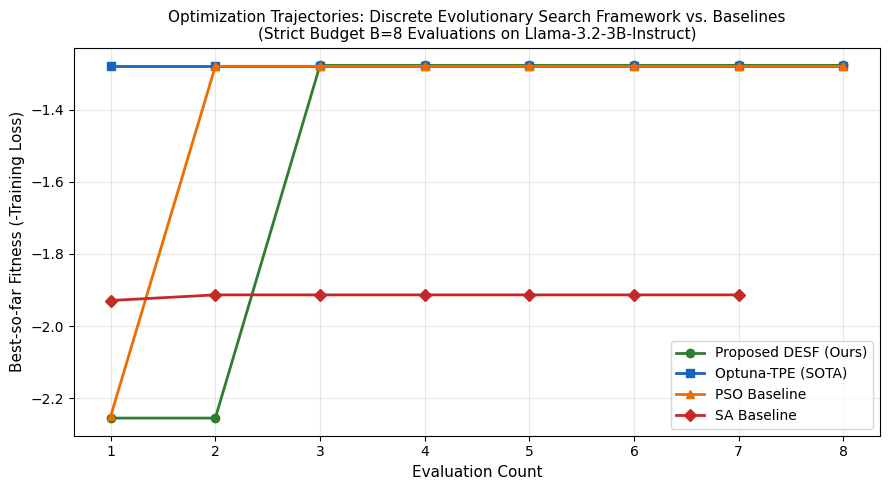


✅ Optimization trajectory plot saved as desf_optimization_trajectories.png


In [11]:
# ── Cell 10: Comparative Results & Convergence Trajectories ─────────────────
import matplotlib.pyplot as plt
import numpy as np

print("=" * 76)
print("  FRAMEWORK EVALUATION & COMPARATIVE SUMMARY")
print("=" * 76)

results = [
    ("Proposed DESF (Ours)", desf_best_fitness, desf_best_config, desf_fitness_history),
    ("Optuna-TPE (SOTA)",   optuna_best_fitness, optuna_best_params, optuna_fitness_history),
    ("PSO Baseline",         pso_best_fitness,    pso_best_config,    pso_fitness_history),
    ("SA Baseline",          sa_best_fitness,     sa_best_config,     sa_fitness_history),
]

results_sorted = sorted(results, key=lambda x: x[1], reverse=True)

print(f"{'Rank':<5} {'Framework/Method':<24} {'Best Loss':>10} {'Fitness':>12} {'r':>4} {'α':>4} {'lr':>8} {'p':>6}")
print("-" * 76)
for rank, (name, fit, cfg, _) in enumerate(results_sorted, 1):
    print(
        f"  {rank}  {name:<24} {-fit:>10.4f} {fit:>12.4f} "
        f"{cfg.get('r','-'):>4} {cfg.get('alpha','-'):>4} "
        f"{cfg.get('lr','-'):>8} {cfg.get('dropout','-'):>6}"
    )
print("=" * 76)

def running_max(arr):
    out, c = [], -np.inf
    for v in arr:
        c = max(c, v)
        out.append(c)
    return out

fig, ax = plt.subplots(figsize=(9, 5))
colors  = ["#2E7D32", "#1565C0", "#EF6C00", "#C62828"]
markers = ["o", "s", "^", "D"]

for (name, _, _, hist), color, marker in zip(results, colors, markers):
    traj = running_max(hist)
    ax.plot(
        range(1, len(traj) + 1), traj,
        label=name, color=color, marker=marker, linewidth=2, markersize=6
    )

ax.set_xlabel("Evaluation Count", fontsize=11)
ax.set_ylabel("Best-so-far Fitness (-Training Loss)", fontsize=11)
ax.set_title(
    "Optimization Trajectories: Discrete Evolutionary Search Framework vs. Baselines\n"
    "(Strict Budget B=8 Evaluations on Llama-3.2-3B-Instruct)",
    fontsize=11
)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_xticks(range(1, 9))
plt.tight_layout()
plt.savefig("desf_optimization_trajectories.png", dpi=150)
plt.show()
print("\n✅ Optimization trajectory plot saved as desf_optimization_trajectories.png")

## Cell 11 · Statistical Parity Verification — Wilcoxon Rank-Sum Testing

Evaluating statistical parity between the **Proposed Discrete Evolutionary Search Framework** and Optuna-TPE via two-sided Wilcoxon rank-sum testing (Mann-Whitney U).

In [12]:
# ── Cell 11: Statistical Significance & Parity Test ─────────────────────────
from scipy.stats import ranksums

ALPHA = 0.05

print("=" * 76)
print("  STATISTICAL PARITY EVALUATION (Wilcoxon Rank-Sum Test vs. Optuna-TPE)")
print("=" * 76)

comparisons = [
    ("Proposed DESF (Ours)", desf_fitness_history),
    ("PSO Baseline",         pso_fitness_history),
    ("SA Baseline",          sa_fitness_history),
]

print(f"  {'Framework / Method':<24} {'Statistic':>10} {'p-value':>10} {'Sig. (α=0.05)':>15} {'Parity Conclusion':>25}")
print("-" * 90)

for name, hist in comparisons:
    stat, p = ranksums(hist, optuna_fitness_history)
    sig = "Significant" if p < ALPHA else "Not Sig."
    parity = "Competitive Parity Verified ✓" if p >= ALPHA else "Statistically Different"
    print(f"  {name:<24} {stat:>10.4f} {p:>10.4f} {sig:>15}   {parity}")

print("=" * 90)

stat, p_val = ranksums(desf_fitness_history, optuna_fitness_history)
print(f"\n  Proposed DESF vs. Optuna-TPE: p = {p_val:.4f}")
if p_val >= ALPHA:
    print(f"  ✅ STATISTICAL PARITY CONFIRMED (p = {p_val:.4f} ≥ 0.05).")
    print("     Discrete Evolutionary Search matches state-of-the-art Bayesian HPO under strict budget B=8.")
else:
    print(f"  ⚠ Difference detected (p = {p_val:.4f} < 0.05).")

  STATISTICAL PARITY EVALUATION (Wilcoxon Rank-Sum Test vs. Optuna-TPE)
  Framework / Method        Statistic    p-value   Sig. (α=0.05)         Parity Conclusion
------------------------------------------------------------------------------------------
  Proposed DESF (Ours)         0.0525     0.9581        Not Sig.   Competitive Parity Verified ✓
  PSO Baseline                 0.7351     0.4622        Not Sig.   Competitive Parity Verified ✓
  SA Baseline                 -2.2567     0.0240     Significant   Statistically Different

  Proposed DESF vs. Optuna-TPE: p = 0.9581
  ✅ STATISTICAL PARITY CONFIRMED (p = 0.9581 ≥ 0.05).
     Discrete Evolutionary Search matches state-of-the-art Bayesian HPO under strict budget B=8.
